<a href="https://colab.research.google.com/github/swetha-off/DSA0302-NLP/blob/main/ASSIGNMENT_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**TASK 1**

In [ ]:

# TASK 1: CONTEXT-FREE GRAMMAR DESIGN

import nltk
from nltk import CFG, ChartParser

# ---------------------------------
# 1. DEFINE CFG RULES
# ---------------------------------

grammar_text = r"""
S -> DECL | IMP | YNQ | WHQ

DECL -> NPsg VPsg
DECL -> NPpl VPpl
DECL -> NP VP

IMP -> Vbase NP
IMP -> Vbase NP PP
IMP -> Vbase PP
IMP -> Please Vbase NP

YNQ -> Auxsg NP VPbase
YNQ -> Auxpl NP VPbase
YNQ -> Auxsg PronSub VPbase

WHQ -> Whword Auxsg NP VPbase
WHQ -> Whword Auxpl NP VPbase
WHQ -> Whword VPsg
WHQ -> Whword Auxsg NP VPbase PP

NP -> NPsg | NPpl | NPobj | NPpron
NPsg -> DetS Nsg
NPsg -> DetS AdjP Nsg
NPsg -> DetS Nsg PP
NPsg -> Nsg
NPsg -> Nsg PP

NPpl -> DetP Npl
NPpl -> DetP AdjP Npl
NPpl -> Npl
NPpl -> Npl PP

NPobj -> DetS Nsg
NPobj -> DetP Npl
NPobj -> DetS AdjP Nsg
NPobj -> DetP AdjP Npl
NPobj -> PronObj

NPpron -> PronSub
NPpron -> PronObj

VP -> VPsg | VPpl | VPbase
VPsg -> Vsg
VPsg -> Vsg NPobj
VPsg -> Vsg NPobj PP
VPsg -> Vsg PP
VPsg -> Vsg AdjP
VPsg -> Auxsg Vbase
VPsg -> Auxsg Vbase NPobj

VPpl -> Vpl
VPpl -> Vpl NPobj
VPpl -> Vpl NPobj PP
VPpl -> Vpl PP
VPpl -> Vpl AdjP

VPbase -> Vbase
VPbase -> Vbase NPobj
VPbase -> Vbase NPobj PP
VPbase -> Vbase PP
VPbase -> Vbase AdjP
VPbase -> Vbase Sbar

PP -> Prep NP
PP -> Prep NP PP

AdjP -> Adj
AdjP -> Adv Adj
AdjP -> Adj PP

Sbar -> Comp S
Sbar -> Rel S

DECL -> NP VP
DECL -> NP VP Conj NP
NP -> NP Conj NP
VP -> VP Conj VP
NPsg -> DetS Nsg Rel S
NPpl -> DetP Npl Rel S

PronSub -> I
PronSub -> He
PronSub -> She
PronSub -> They
PronSub -> We

PronObj -> Me
PronObj -> Him
PronObj -> Her
PronObj -> Them
PronObj -> Us

# ---------------------------------
# 2. LEXICON
# ---------------------------------

DetS -> 'the' | 'a' | 'an' | 'this' | 'my'
DetP -> 'the' | 'these' | 'those' | 'my'

Nsg -> 'student' | 'timetable' | 'examination' | 'hostel'
Nsg -> 'fee' | 'library' | 'placement' | 'notice'
Nsg -> 'room' | 'seminar' | 'book' | 'class'
Nsg -> 'result' | 'course' | 'department' | 'account'
Nsg -> 'application' | 'certificate' | 'scholarship'
Nsg -> 'deadline' | 'ticket' | 'query' | 'professor'

Npl -> 'students' | 'examinations' | 'hostels'
Npl -> 'fees' | 'timetables' | 'placements'
Npl -> 'notices' | 'rooms' | 'seminars'
Npl -> 'books' | 'classes' | 'results'
Npl -> 'courses' | 'departments' | 'accounts'
Npl -> 'applications' | 'certificates' | 'scholarships'
Npl -> 'deadlines' | 'queries' | 'professors'

Vsg -> 'is' | 'has' | 'shows' | 'starts' | 'provides' | 'checks' | 'pays'
Vpl -> 'are' | 'have' | 'show' | 'start' | 'provide'

Vbase -> 'show' | 'check' | 'find' | 'book'
Vbase -> 'submit' | 'explain' | 'tell' | 'display'
Vbase -> 'cancel' | 'confirm' | 'provide' | 'help'
Vbase -> 'open' | 'visit' | 'print' | 'download'
Vbase -> 'know' | 'give' | 'need' | 'pay'
Vbase -> 'attend' | 'register' | 'contact' | 'apply'
Vbase -> 'reschedule' | 'update' | 'return'

Prep -> 'in' | 'on' | 'at' | 'near' | 'with'
Prep -> 'for' | 'from' | 'to' | 'by' | 'about'
Prep -> 'before' | 'after' | 'during' | 'of'

Adj -> 'late' | 'available' | 'new' | 'important'
Adj -> 'final' | 'internal' | 'online' | 'academic'
Adj -> 'library' | 'hostel' | 'exam' | 'semester'

Adv -> 'very' | 'really' | 'quite'

Auxsg -> 'does' | 'is' | 'has' | 'can' | 'will'
Auxpl -> 'do' | 'are' | 'have' | 'can' | 'will'

Whword -> 'what' | 'when' | 'where' | 'which' | 'who' | 'how'

Comp -> 'that' | 'because' | 'if' | 'whether'
Rel -> 'that' | 'which' | 'who'

Conj -> 'and' | 'or' | 'but'

Please -> 'please'

I -> 'i'
He -> 'he'
She -> 'she'
They -> 'they'
We -> 'we'
Me -> 'me'
Him -> 'him'
Her -> 'her'
Them -> 'them'
Us -> 'us'
"""

grammar = CFG.fromstring(grammar_text)

print("CONTEXT FREE GRAMMAR CREATED")
print("Number of grammar productions:", len(grammar.productions()))

# ---------------------------------
# 3. COUNT LEXICON WORDS
# ---------------------------------

lexicon_words = set()

for production in grammar.productions():
    if production.is_lexical():
        lexicon_words.add(str(production.rhs()[0]))

print("Number of unique lexical words:", len(lexicon_words))

print("\nLEXICON WORDS:")
print(sorted(lexicon_words))

# ---------------------------------
# 4. DISPLAY GRAMMAR CATEGORIES
# ---------------------------------

print("\nGRAMMAR NON-TERMINALS:")

nonterminals = set(production.lhs() for production in grammar.productions())
for symbol in sorted(nonterminals, key=lambda s: s.symbol()):
    print(symbol)

# ---------------------------------
# 5. TEST SENTENCES
# ---------------------------------

parser = ChartParser(grammar)

sentences = [
    "the student checks the timetable",
    "the students show the notices",
    "please check the examination timetable",
    "show the students with the late fee notice",
    "the professor provides the certificate",
    "the library is available",
    "students attend the seminar",
    "the hostel provides rooms",
    "the student pays the fee",
    "the examinations start after the semester"
]

print("\nSENTENCE PARSING RESULTS")

for sentence in sentences:
    tokens = sentence.lower().split()
    trees = list(parser.parse(tokens))

    print("\nSentence:", sentence)
    print("Number of parse trees:", len(trees))

    if trees:
        print(trees[0])
    else:
        print("No parse found")


CONTEXT FREE GRAMMAR CREATED
Number of grammar productions: 240
Number of unique lexical words: 142

LEXICON WORDS:
['a', 'about', 'academic', 'account', 'accounts', 'after', 'an', 'and', 'application', 'applications', 'apply', 'are', 'at', 'attend', 'available', 'because', 'before', 'book', 'books', 'but', 'by', 'can', 'cancel', 'certificate', 'certificates', 'check', 'checks', 'class', 'classes', 'confirm', 'contact', 'course', 'courses', 'deadline', 'deadlines', 'department', 'departments', 'display', 'do', 'does', 'download', 'during', 'exam', 'examination', 'examinations', 'explain', 'fee', 'fees', 'final', 'find', 'for', 'from', 'give', 'has', 'have', 'he', 'help', 'her', 'him', 'hostel', 'hostels', 'how', 'i', 'if', 'important', 'in', 'internal', 'is', 'know', 'late', 'library', 'me', 'my', 'near', 'need', 'new', 'notice', 'notices', 'of', 'on', 'online', 'open', 'or', 'pay', 'pays', 'placement', 'placements', 'please', 'print', 'professor', 'professors', 'provide', 'provides', 

**TASK 2**

In [ ]:

# TASK 2: DERIVATIONS AND PARSE TREES

from nltk import Tree

# ---------------------------------
# 1. SELECT FIVE SENTENCES
# ---------------------------------

test_sentences = [
    "the student checks the timetable",
    "the students show the notices",
    "please check the examination timetable",
    "the library is available",
    "the student pays the fee"
]

# ---------------------------------
# 2. GENERATE DERIVATIONS
# ---------------------------------

def get_derivation(tree, mode="left"):
    productions = []

    def collect(node):
        if isinstance(node, Tree):
            productions.append(
                (node.label(), list(node))
            )

            children = list(node)

            if mode == "right":
                children = children[::-1]

            for child in children:
                collect(child)

    collect(tree)

    result = ["S"]
    steps = ["S"]

    for lhs, rhs in productions:
        index = None

        positions = range(len(result))

        if mode == "right":
            positions = range(len(result)-1, -1, -1)

        for i in positions:
            if isinstance(result[i], str) and result[i] == lhs:
                index = i
                break

        if index is not None:
            result = result[:index] + rhs + result[index+1:]
            steps.append(" ".join(
                str(x.label()) if isinstance(x, Tree)
                else str(x)
                for x in result
            ))

    return steps

# ---------------------------------
# 3. TREE MEASUREMENTS
# ---------------------------------

def tree_metrics(tree):
    height = tree.height()
    nodes = sum(1 for subtree in tree.subtrees())
    leaves = len(tree.leaves())
    rule_applications = len(tree.productions())

    return height, nodes, leaves, rule_applications

# ---------------------------------
# 4. PARSE FIVE SENTENCES
# ---------------------------------

for sentence in test_sentences:

    print("\n" + "="*55)
    print("SENTENCE:", sentence)

    tokens = sentence.split()
    parsed_trees = list(parser.parse(tokens))

    if not parsed_trees:
        print("No parse found")
        continue

    tree = parsed_trees[0]

    print("\nBRACKETED PARSE TREE:")
    print(tree.pformat(margin=100))

    print("\nLEFTMOST DERIVATION:")
    for step in get_derivation(tree, "left"):
        print(step)

    print("\nRIGHTMOST DERIVATION:")
    for step in get_derivation(tree, "right"):
        print(step)

    height, nodes, leaves, rules = tree_metrics(tree)

    print("\nTREE MEASUREMENTS")
    print("Tree height:", height)
    print("Number of nonterminal nodes:", nodes)
    print("Number of words:", leaves)
    print("Rule applications:", rules)

    print("\nTREE DIAGRAM:")
    tree.pretty_print()

# ---------------------------------
# 5. AMBIGUITY TEST
# ---------------------------------

ambiguous_sentences = [
    "show the students with the late fee notice",
    "book the room near the library for the seminar"
]

print("\nAMBIGUITY ANALYSIS")

for sentence in ambiguous_sentences:

    print("\nSentence:", sentence)

    tokens = sentence.split()
    trees = list(parser.parse(tokens))

    print("Number of parse trees:", len(trees))

    for i, tree in enumerate(trees[:2], start=1):
        print("\nParse Tree", i)
        print(tree.pformat(margin=100))
        tree.pretty_print()

    if len(trees) > 1:
        print("Result: Structurally ambiguous sentence")
    else:
        print("Result: One parse found by the current grammar")

# ---------------------------------
# 6. STRING MEMBERSHIP TEST
# ---------------------------------

def check_sentence(sentence):
    tokens = sentence.lower().split()
    results = list(parser.parse(tokens))

    if results:
        return "Sentence belongs to the grammar L(G)"
    else:
        return "Sentence does not belong to the grammar L(G)"

print("\nSTRING MEMBERSHIP TEST")

print(check_sentence("the student checks the timetable"))
print(check_sentence("students the timetable checks"))



SENTENCE: the student checks the timetable

BRACKETED PARSE TREE:
(S (DECL (NPsg (DetS the) (Nsg student)) (VPsg (Vsg checks) (NPobj (DetS the) (Nsg timetable)))))

LEFTMOST DERIVATION:
S
DECL

RIGHTMOST DERIVATION:
S
DECL

TREE MEASUREMENTS
Tree height: 6
Number of nonterminal nodes: 10
Number of words: 5
Rule applications: 10

TREE DIAGRAM:
                    S                        
                    |                         
                   DECL                      
       _____________|_____                    
      |                  VPsg                
      |              _____|_____              
     NPsg           |         NPobj          
  ____|______       |      _____|_______      
DetS        Nsg    Vsg   DetS          Nsg   
 |           |      |     |             |     
the       student checks the        timetable


SENTENCE: the students show the notices

BRACKETED PARSE TREE:
(S (DECL (NPpl (DetP the) (Npl students)) (VPpl (Vpl show) (NPobj (DetP the) (

**TASK 3**

In [ ]:

# TASK 3: SENTENCE-LEVEL CONSTRUCTIONS

from nltk import CFG, ChartParser

# ---------------------------------
# 1. EXTEND THE ORIGINAL GRAMMAR
# ---------------------------------

extra_rules = nltk.CFG.fromstring(r"""
# Subject WH questions
WHQ -> Whword Vsg NPobj

# Object WH questions
WHQ -> Whword Auxsg NP VPbase

# Yes/no questions
YNQ -> Auxsg NP VPbase
YNQ -> Auxpl NP VPbase

# Imperatives
IMP -> Vbase NP
IMP -> Please Vbase NP

# Subordinate clauses
VPsg -> Vsg Sbar
VPpl -> Vpl Sbar

# Relative clauses
NPsg -> DetS Nsg Rel VPpl
NPpl -> DetP Npl Rel VPpl

# Additional verbs
Vsg -> 'knows' | 'explains'
Vpl -> 'know' | 'explain'
Vbase -> 'start' | 'postponed'
Auxpl -> 'were'
Whword -> 'why'
""")

# Combine original and additional rules
extended_grammar = CFG(
    grammar.start(),
    grammar.productions() + extra_rules.productions()
)

extended_parser = ChartParser(extended_grammar)

# ---------------------------------
# 2. CREATE SENTENCE TYPES
# ---------------------------------

sentence_types = {
    "Declarative": [
        "the student checks the timetable",
        "the library is available",
        "the students show the notices"
    ],

    "Imperative": [
        "check the timetable",
        "show the students",
        "please check the examination timetable"
    ],

    "Yes/No Questions": [
        "does the student check the timetable",
        "do the students show the notices",
        "does the library provide books"
    ],

    "Wh Questions": [
        "what does the student check",
        "who checks the timetable",
        "when does the student pay the fee"
    ],

    "Subordinate Clauses": [
        "the student knows that the examinations start",
        "the professor explains that the timetable is available"
    ],

    "Relative Clauses": [
        "the examinations that were postponed",
        "the students that were postponed"
    ]
}

# ---------------------------------
# 3. PARSE EACH CONSTRUCTION
# ---------------------------------

for category, sentences in sentence_types.items():

    print("\n" + "="*60)
    print("SENTENCE TYPE:", category)
    print("="*60)

    for sentence in sentences:

        tokens = sentence.split()
        trees = list(extended_parser.parse(tokens))

        print("\nSentence:", sentence)

        if trees:
            print("Parsing successful")
            print("Number of parse trees:", len(trees))

            print("\nParse Tree:")
            print(trees[0].pformat(margin=100))

            trees[0].pretty_print()

        else:
            print("No parse found using the current grammar")

# ---------------------------------
# 4. COMPARE SENTENCE CONSTRUCTIONS
# ---------------------------------

print("\nSENTENCE CONSTRUCTION COMPARISON")

comparison = {
    "Declarative": "Subject + Verb + Object",
    "Imperative": "Verb + Object",
    "Yes/No Question": "Auxiliary + Subject + Verb",
    "Wh Question": "Wh-word + Auxiliary + Subject + Verb",
    "Subordinate": "Main clause + Complementizer + Subordinate clause",
    "Relative": "Noun phrase + Relative word + Clause"
}

for category, structure in comparison.items():
    print(category, ":", structure)

# ---------------------------------
# 5. COORDINATION TEST
# ---------------------------------

coordination_sentences = [
    "the student checks the timetable",
    "the students show the notices"
]

print("\nCOORDINATION EXAMPLE")

for sentence in coordination_sentences:
    print(sentence)

print("Coordination rule:")
print("NP -> NP Conj NP")
print("VP -> VP Conj VP")

# ---------------------------------
# 6. FINAL RESULT
# ---------------------------------

print("\nTASK 3 COMPLETED")
print("Declarative rules tested")
print("Imperative rules tested")
print("Yes/No question rules tested")
print("Wh-question rules tested")
print("Subordinate and relative clause rules tested")



SENTENCE TYPE: Declarative

Sentence: the student checks the timetable
Parsing successful
Number of parse trees: 3

Parse Tree:
(S (DECL (NPsg (DetS the) (Nsg student)) (VPsg (Vsg checks) (NPobj (DetS the) (Nsg timetable)))))
                    S                        
                    |                         
                   DECL                      
       _____________|_____                    
      |                  VPsg                
      |              _____|_____              
     NPsg           |         NPobj          
  ____|______       |      _____|_______      
DetS        Nsg    Vsg   DetS          Nsg   
 |           |      |     |             |     
the       student checks the        timetable


Sentence: the library is available
Parsing successful
Number of parse trees: 3

Parse Tree:
(S (DECL (NPsg (DetS the) (Nsg library)) (VPsg (Vsg is) (AdjP (Adj available)))))
                   S                     
                   |                      
 

**TASK 4**

In [ ]:

import nltk
from nltk import CFG, ChartParser

# --------------------------------
# 1. BASELINE GRAMMAR
# --------------------------------

baseline_grammar = CFG.fromstring("""
S -> NP VP
NP -> Det N
NP -> Pron
VP -> V
VP -> V NP

Det -> 'the' | 'a'
N -> 'student' | 'students' | 'form' | 'forms'
Pron -> 'he' | 'they' | 'him' | 'them'
V -> 'submit' | 'submits' | 'check' | 'checks'
""")

baseline_parser = ChartParser(baseline_grammar)

# --------------------------------
# 2. AGREEMENT-AWARE GRAMMAR
# --------------------------------

agreement_grammar = CFG.fromstring("""
S -> NPsg VPsg
S -> NPpl VPpl

NPsg -> DetS Nsg
NPpl -> DetP Npl

NPsg -> PronS
NPpl -> PronP

VPsg -> Vsg
VPsg -> Vsg NPobj

VPpl -> Vpl
VPpl -> Vpl NPobj

NPobj -> DetS Nsg
NPobj -> DetP Npl
NPobj -> PronO

DetS -> 'the' | 'a'
DetP -> 'the' | 'these' | 'those'

Nsg -> 'student' | 'form'
Npl -> 'students' | 'forms'

Vsg -> 'submits' | 'checks'
Vpl -> 'submit' | 'check'

PronS -> 'he' | 'they'
PronP -> 'they'
PronO -> 'him' | 'them'
""")

agreement_parser = ChartParser(agreement_grammar)

# --------------------------------
# 3. TEST SENTENCES
# --------------------------------

grammatical = [
    "the student submits the form",
    "the students submit the forms",
    "he checks the form",
    "they check the forms",
    "the student checks the forms",
    "the students submit the form"
]

ungrammatical = [
    "the students submits the form",
    "the student submit the form",
    "a students submit the form",
    "the student submits forms",
    "him checks the form",
    "he check the forms"
]

# --------------------------------
# 4. TESTING FUNCTION
# --------------------------------

def test_sentences(sentences, parser):
    results = []

    for sentence in sentences:
        tokens = sentence.split()
        trees = list(parser.parse(tokens))

        status = "Accepted" if trees else "Rejected"
        results.append((sentence, status))

    return results

print("BASELINE GRAMMAR RESULTS")

for sentence, result in (
    test_sentences(grammatical + ungrammatical,
                   baseline_parser)
):
    print(sentence, ":", result)

print("\nAGREEMENT-AWARE GRAMMAR RESULTS")

for sentence, result in (
    test_sentences(grammatical + ungrammatical,
                   agreement_parser)
):
    print(sentence, ":", result)

# --------------------------------
# 5. RULE COUNT AND RULE EXPLOSION
# --------------------------------

print("\nAGREEMENT RULE ANALYSIS")

print("Baseline S rules:", 1)
print("Agreement-aware S rules:", 2)

persons = 3
numbers = 2
cases = 2
genders = 3

combinations = persons * numbers * cases * genders

print("Person categories:", persons)
print("Number categories:", numbers)
print("Case categories:", cases)
print("Gender categories:", genders)

print("Total possible feature combinations:",
      combinations)

print("\nFeature-based grammar can use shared rules")
print("instead of writing a separate rule for every combination.")

# --------------------------------
# 6. FINAL RESULT
# --------------------------------

print("\nTASK 4 COMPLETED")


BASELINE GRAMMAR RESULTS
the student submits the form : Accepted
the students submit the forms : Accepted
he checks the form : Accepted
they check the forms : Accepted
the student checks the forms : Accepted
the students submit the form : Accepted
the students submits the form : Accepted
the student submit the form : Accepted
a students submit the form : Accepted
the student submits forms : Rejected
him checks the form : Accepted
he check the forms : Accepted

AGREEMENT-AWARE GRAMMAR RESULTS
the student submits the form : Accepted
the students submit the forms : Accepted
he checks the form : Accepted
they check the forms : Accepted
the student checks the forms : Accepted
the students submit the form : Accepted
the students submits the form : Rejected
the student submit the form : Rejected
a students submit the form : Rejected
the student submits forms : Rejected
him checks the form : Rejected
he check the forms : Rejected

AGREEMENT RULE ANALYSIS
Baseline S rules: 1
Agreement-aware S r

**TASK 5**

In [ ]:

import nltk
from nltk import CFG, ChartParser

# --------------------------------
# 1. SUBCATEGORIZATION GRAMMAR
# --------------------------------

grammar_text = """
S -> NP VP

NP -> Det N
NP -> Pron

VP -> Vintr
VP -> Vtrans NP
VP -> Vditrans Pron NP
VP -> Vcomp Pron Sbar
VP -> Vpp Prep NP

VP -> Vtrans NP PP
VP -> Vintr PP

Sbar -> Comp S

Det -> 'the' | 'a'
N -> 'portal' | 'form' | 'receipt'
N -> 'fee' | 'room' | 'hostel'
N -> 'student' | 'notice'

Pron -> 'the' | 'me' | 'him'

Vintr -> 'crashed' | 'arrived'
Vtrans -> 'submit' | 'submitted'
Vtrans -> 'checked' | 'check'
Vditrans -> 'send' | 'sent'
Vcomp -> 'tell' | 'told'
Vpp -> 'apply' | 'applied'

Prep -> 'for' | 'to' | 'in'
Comp -> 'that'
"""

grammar = CFG.fromstring(grammar_text)
parser = ChartParser(grammar)

# --------------------------------
# 2. VERB SUBCATEGORIZATION FRAMES
# --------------------------------

frames = {
    "Intransitive": "Verb + no object",
    "Transitive": "Verb + noun phrase",
    "Ditransitive": "Verb + indirect object + direct object",
    "Sentential": "Verb + sentence complement",
    "PP Complement": "Verb + prepositional phrase"
}

print("VERB SUBCATEGORIZATION FRAMES")

for name, frame in frames.items():
    print(name, ":", frame)

# --------------------------------
# 3. TEST SENTENCES
# --------------------------------

sentences = [
    "the portal crashed",
    "the student submitted the form",
    "the student sent me the receipt",
    "the student told me that the fee",
    "the student applied for the hostel",
    "the student submitted",
    "the portal crashed the form",
    "the student checked the notice"
]

print("\nPARSING RESULTS")

for sentence in sentences:
    trees = list(parser.parse(sentence.split()))

    print("\nSentence:", sentence)

    if trees:
        print("Accepted")
        print("Parse tree:")
        print(trees[0])
    else:
        print("Rejected")

# --------------------------------
# 4. COMPLEMENT AND ADJUNCT EXAMPLES
# --------------------------------

print("\nCOMPLEMENT AND ADJUNCT ANALYSIS")

examples = {
    "Submit the form": "The form is a required complement.",
    "Apply for a hostel room": "For a hostel room is selected by apply.",
    "The student studies in the library":
        "In the library is an optional location adjunct.",
    "The student submitted the form yesterday":
        "Yesterday is an optional time adjunct."
}

for sentence, explanation in examples.items():
    print("\n", sentence)
    print(explanation)

# --------------------------------
# 5. MULTIPLE VERB FRAMES
# --------------------------------

print("\nMULTIPLE VERB FRAMES")

print("Book:")
print("1. Book a room - Transitive")
print("2. Book for the seminar - PP construction")

print("Check:")
print("1. Check the timetable - Transitive")
print("2. Check carefully - Intransitive with adverb")

print("\nTASK 5 COMPLETED")


VERB SUBCATEGORIZATION FRAMES
Intransitive : Verb + no object
Transitive : Verb + noun phrase
Ditransitive : Verb + indirect object + direct object
Sentential : Verb + sentence complement
PP Complement : Verb + prepositional phrase

PARSING RESULTS

Sentence: the portal crashed
Accepted
Parse tree:
(S (NP (Det the) (N portal)) (VP (Vintr crashed)))

Sentence: the student submitted the form
Accepted
Parse tree:
(S
  (NP (Det the) (N student))
  (VP (Vtrans submitted) (NP (Det the) (N form))))

Sentence: the student sent me the receipt
Accepted
Parse tree:
(S
  (NP (Det the) (N student))
  (VP (Vditrans sent) (Pron me) (NP (Det the) (N receipt))))

Sentence: the student told me that the fee
Rejected

Sentence: the student applied for the hostel
Accepted
Parse tree:
(S
  (NP (Det the) (N student))
  (VP (Vpp applied) (Prep for) (NP (Det the) (N hostel))))

Sentence: the student submitted
Rejected

Sentence: the portal crashed the form
Rejected

Sentence: the student checked the notice
Acc

**TASK 6**

In [ ]:

import nltk
from nltk import CFG
from nltk.parse import RecursiveDescentParser

# --------------------------------
# 1. TOP-DOWN GRAMMAR
# --------------------------------

grammar_text = """
S -> NP VP

NP -> Det N
NP -> Det N PP

VP -> V
VP -> V NP
VP -> V NP PP
VP -> V PP

PP -> Prep NP

Det -> 'the' | 'a'
N -> 'student' | 'timetable' | 'room'
N -> 'library' | 'notice' | 'seminar'

V -> 'checks' | 'books' | 'shows'
V -> 'visits'

Prep -> 'with' | 'near' | 'for'
"""

grammar = CFG.fromstring(grammar_text)

# --------------------------------
# 2. RECURSIVE DESCENT PARSER
# --------------------------------

parser = RecursiveDescentParser(grammar)

# --------------------------------
# 3. TEST SENTENCES
# --------------------------------

sentences = [
    "the student checks the timetable",
    "the student books the room near the library"
]

for sentence in sentences:

    print("\n" + "="*55)
    print("SENTENCE:", sentence)

    tokens = sentence.split()

    print("\nTOP-DOWN PARSING TRACE:")

    parser.trace(2)

    trees = list(parser.parse(tokens))

    if trees:
        print("\nPARSE SUCCESSFUL")
        print("Number of parse trees:", len(trees))

        for i, tree in enumerate(trees, 1):
            print("\nParse Tree", i)
            print(tree)
            tree.pretty_print()

    else:
        print("\nSentence cannot be parsed.")

# --------------------------------
# 4. AMBIGUITY TEST
# --------------------------------

ambiguous = "the student books the room near the library"

trees = list(parser.parse(ambiguous.split()))

print("\nAMBIGUITY ANALYSIS")
print("Sentence:", ambiguous)
print("Number of parse trees:", len(trees))

for i, tree in enumerate(trees, 1):
    print("\nInterpretation", i)
    print(tree)

# --------------------------------
# 5. LEFT RECURSION EXAMPLE
# --------------------------------

print("\nLEFT RECURSION PROBLEM")

left_recursive_grammar = CFG.fromstring("""
S -> NP
NP -> NP PP
NP -> Det N
PP -> Prep NP
Det -> 'the'
N -> 'room' | 'library'
Prep -> 'near'
""")

print("Left-recursive rule:")
print("NP -> NP PP")

print("This rule can repeatedly expand NP")
print("before consuming any input word.")

# --------------------------------
# 6. LEFT RECURSION ELIMINATION
# --------------------------------

print("\nLEFT RECURSION ELIMINATION")

new_grammar = CFG.fromstring("""
S -> NP
NP -> Det N PPSEQ
PPSEQ -> PP PPSEQ
PPSEQ ->
PP -> Prep NP
Det -> 'the'
N -> 'room' | 'library'
Prep -> 'near'
""")

new_parser = RecursiveDescentParser(new_grammar)

sentence = "the room near the library"

new_trees = list(new_parser.parse(sentence.split()))

print("Sentence:", sentence)
print("Number of parse trees:", len(new_trees))

for tree in new_trees:
    print(tree)

# --------------------------------
# 7. COMPLEXITY ANALYSIS
# --------------------------------

print("\nPARSING COMPLEXITY")

print("Top-down parsing explores grammar expansions.")
print("Worst-case time for naive backtracking can be exponential.")

for k in range(1, 6):
    possibilities = 2 ** k
    print("Number of PP phrases:", k,
          "Possible attachment patterns:", possibilities)

print("\nTASK 6 COMPLETED")



SENTENCE: the student checks the timetable

TOP-DOWN PARSING TRACE:
Parsing 'the student checks the timetable'
    [ * S ]
  E [ * NP VP ]
  E [ * Det N VP ]
  E [ * 'the' N VP ]
  M [ 'the' * N VP ]
  E [ 'the' * 'student' VP ]
  M [ 'the' 'student' * VP ]
  E [ 'the' 'student' * V ]
  E [ 'the' 'student' * 'checks' ]
  M [ 'the' 'student' 'checks' ]
  E [ 'the' 'student' * 'books' ]
  E [ 'the' 'student' * 'shows' ]
  E [ 'the' 'student' * 'visits' ]
  E [ 'the' 'student' * V NP ]
  E [ 'the' 'student' * 'checks' NP ]
  M [ 'the' 'student' 'checks' * NP ]
  E [ 'the' 'student' 'checks' * Det N ]
  E [ 'the' 'student' 'checks' * 'the' N ]
  M [ 'the' 'student' 'checks' 'the' * N ]
  E [ 'the' 'student' 'checks' 'the' * 'student' ]
  E [ 'the' 'student' 'checks' 'the' * 'timetable' ]
  M [ 'the' 'student' 'checks' 'the' 'timetable' ]
  + [ 'the' 'student' 'checks' 'the' 'timetable' ]
  E [ 'the' 'student' 'checks' 'the' * 'room' ]
  E [ 'the' 'student' 'checks' 'the' * 'library' ]
  E

**TASK 7**

In [ ]:
import nltk
from nltk import CFG
from nltk.parse import EarleyChartParser

# Helpdesk grammar
grammar = CFG.fromstring("""
S -> NP VP
NP -> Det N
NP -> NP PP
VP -> V NP
VP -> VP PP
PP -> P NP

Det -> 'the' | 'a'
N -> 'student' | 'timetable' | 'room' | 'library'
V -> 'checks' | 'books'
P -> 'near' | 'in'
""")

parser = EarleyChartParser(grammar)

# Six or more words
sentence = "the student books the room near the library".split()

print("TASK 7 - EARLEY PARSING")
print("Sentence:", " ".join(sentence))

# Create Earley chart
chart = parser.chart_parse(sentence)

print("\nEARLEY CHART ENTRIES")

for position in range(len(sentence) + 1):
    print("\nS[{}]".format(position))

    for edge in chart.edges():
        if edge.end() == position:
            status = "COMPLETE" if edge.is_complete() else "INCOMPLETE"
            print("State:", edge,
                  "| Origin:", edge.start(),
                  "| Status:", status)

print("\nTotal Earley States:", len(chart.edges()))

# Recover parse trees
trees = list(chart.parses(grammar.start()))

print("\nNumber of Parse Trees:", len(trees))

for i, tree in enumerate(trees, 1):
    print("\nParse Tree", i)
    tree.pretty_print()

# Show ambiguous PP attachment
print("\nAMBIGUOUS ATTACHMENT TEST")

ambiguous_sentence = "the student books the room near the library".split()

ambiguous_chart = parser.chart_parse(ambiguous_sentence)
ambiguous_trees = list(ambiguous_chart.parses(grammar.start()))

print("Sentence:", " ".join(ambiguous_sentence))
print("Number of possible parses:", len(ambiguous_trees))

for i, tree in enumerate(ambiguous_trees, 1):
    print("\nAmbiguous Parse", i)
    tree.pretty_print()

# Left recursion test
print("\nLEFT RECURSION TEST")

left_grammar = CFG.fromstring("""
S -> NP VP
NP -> NP PP
NP -> Det N
VP -> V NP
VP -> VP PP
PP -> P NP
Det -> 'the'
N -> 'student' | 'room' | 'library'
V -> 'books'
P -> 'near'
""")

left_parser = EarleyChartParser(left_grammar)

left_sentence = "the student books the room near the library".split()

left_chart = left_parser.chart_parse(left_sentence)
left_trees = list(left_chart.parses(left_grammar.start()))

print("Left-recursive sentence:", " ".join(left_sentence))
print("Chart states:", len(left_chart.edges()))
print("Parse trees:", len(left_trees))

for tree in left_trees:
    tree.pretty_print()

# Compare with top-down parsing
from nltk.parse import RecursiveDescentParser
import time

topdown_grammar = CFG.fromstring("""
S -> NP VP
NP -> Det N
VP -> V NP
VP -> V NP PP
PP -> P NP
Det -> 'the'
N -> 'student' | 'room' | 'library'
V -> 'books'
P -> 'near'
""")

topdown = RecursiveDescentParser(topdown_grammar)

start = time.perf_counter()
topdown_trees = list(topdown.parse(sentence))
topdown_time = time.perf_counter() - start

start = time.perf_counter()
earley_trees = list(parser.parse(sentence))
earley_time = time.perf_counter() - start

print("\nPARSER COMPARISON")
print("Top-down parse count:", len(topdown_trees))
print("Earley parse count:", len(earley_trees))
print("Top-down time:", round(topdown_time, 6), "seconds")
print("Earley time:", round(earley_time, 6), "seconds")
print("Earley chart states:", len(chart.edges()))

TASK 7 - EARLEY PARSING
Sentence: the student books the room near the library

EARLEY CHART ENTRIES

S[0]
State: [0:0] S  -> * NP VP | Origin: 0 | Status: INCOMPLETE
State: [0:0] NP -> * Det N | Origin: 0 | Status: INCOMPLETE
State: [0:0] NP -> * NP PP | Origin: 0 | Status: INCOMPLETE
State: [0:0] Det -> * 'the' | Origin: 0 | Status: INCOMPLETE

S[1]
State: [0:1] 'the' | Origin: 0 | Status: COMPLETE
State: [0:1] Det -> 'the' * | Origin: 0 | Status: COMPLETE
State: [0:1] NP -> Det * N | Origin: 0 | Status: INCOMPLETE
State: [1:1] N  -> * 'student' | Origin: 1 | Status: INCOMPLETE

S[2]
State: [1:2] 'student' | Origin: 1 | Status: COMPLETE
State: [1:2] N  -> 'student' * | Origin: 1 | Status: COMPLETE
State: [0:2] NP -> Det N * | Origin: 0 | Status: COMPLETE
State: [0:2] S  -> NP * VP | Origin: 0 | Status: INCOMPLETE
State: [0:2] NP -> NP * PP | Origin: 0 | Status: INCOMPLETE
State: [2:2] PP -> * P NP | Origin: 2 | Status: INCOMPLETE
State: [2:2] VP -> * V NP | Origin: 2 | Status: INCOMPL

**TASK 8**

In [ ]:
import nltk
from nltk.featstruct import FeatStruct
from nltk.grammar import FeatureGrammar
from nltk.parse import FeatureChartParser

print("TASK 8 - FEATURE STRUCTURES AND UNIFICATION")

# Five lexical feature structures
lexicon = {
    "student": FeatStruct("[CAT='N', NUM='sg', PER=3, CASE='nom']"),
    "students": FeatStruct("[CAT='N', NUM='pl', PER=3, CASE='nom']"),
    "I": FeatStruct("[CAT='PRON', NUM='sg', PER=1, CASE='nom']"),
    "me": FeatStruct("[CAT='PRON', NUM='sg', PER=1, CASE='obj']"),
    "checks": FeatStruct("[CAT='V', NUM='sg', PER=3, SUBCAT='trans']"),
    "check": FeatStruct("[CAT='V', NUM='pl', PER=3, SUBCAT='trans']"),
    "crashed": FeatStruct("[CAT='V', SUBCAT='intrans']"),
    "submitted": FeatStruct("[CAT='V', SUBCAT='trans']")
}

print("\nLEXICAL FEATURE STRUCTURES")

for word, feature in lexicon.items():
    print(word, ":", feature)

# Unification examples
print("\nUNIFICATION EXAMPLES")

# Example 1: Successful unification
f1 = FeatStruct("[NUM='sg', PER=3]")
f2 = FeatStruct("[NUM='sg', PER=3]")

print("\nExample 1:")
print("Feature 1:", f1)
print("Feature 2:", f2)
print("Result:", f1.unify(f2))

# Example 2: Failed unification
f3 = FeatStruct("[NUM='sg']")
f4 = FeatStruct("[NUM='pl']")

print("\nExample 2:")
print("Feature 1:", f3)
print("Feature 2:", f4)
print("Result:", f3.unify(f4))

# Example 3: Partial unification
f5 = FeatStruct("[NUM='sg']")
f6 = FeatStruct("[NUM='sg', PER=1, CASE='nom']")

print("\nExample 3:")
print("Feature 1:", f5)
print("Feature 2:", f6)
print("Result:", f5.unify(f6))

# Feature-based grammar
feature_grammar_text = r"""
% start S

S -> NP[NUM=?n, PER=?p] VP[NUM=?n, PER=?p]

NP[NUM=?n, PER=?p] -> Det N[NUM=?n, PER=?p]

NP[NUM=sg, PER=1] -> 'I'
NP[NUM=sg, PER=2] -> 'you'
NP[NUM=sg, PER=3] -> 'he'
NP[NUM=pl, PER=3] -> 'students'

VP[NUM=sg, PER=3] -> V[NUM=sg, PER=3]
VP[NUM=sg, PER=3] -> V[NUM=sg, PER=3] NP

VP[NUM=pl, PER=3] -> V[NUM=pl, PER=3]
VP[NUM=pl, PER=3] -> V[NUM=pl, PER=3] NP

Det -> 'the'

N[NUM=sg, PER=3] -> 'student'
N[NUM=pl, PER=3] -> 'students'
N[NUM=sg, PER=3] -> 'timetable'

V[NUM=sg, PER=3] -> 'checks'
V[NUM=pl, PER=3] -> 'check'
"""

feature_grammar = FeatureGrammar.fromstring(feature_grammar_text)

parser = FeatureChartParser(feature_grammar)

# Agreement tests
test_sentences = [
    "the student checks the timetable",
    "the student check the timetable",
    "students check the timetable",
    "students checks the timetable",
    "I check the timetable",
    "he checks the timetable"
]

print("\nAGREEMENT TESTING")

for sentence in test_sentences:
    trees = list(parser.parse(sentence.split()))

    if trees:
        print(sentence, "-> ACCEPTED")
    else:
        print(sentence, "-> REJECTED")

# Subcategorization checking
print("\nSUBCATEGORIZATION TESTING")

subcat = {
    "crashed": "Intransitive - no object",
    "checks": "Transitive - requires object",
    "submitted": "Transitive - requires object",
    "sent": "Ditransitive - requires two complements",
    "told": "Sentential complement"
}

for verb, frame in subcat.items():
    print(verb, "->", frame)

# Display a complete parse
sentence = "the student checks the timetable".split()

trees = list(parser.parse(sentence))

print("\nCOMPLETE FEATURE PARSE")

if trees:
    for tree in trees:
        print(tree)
else:
    print("No valid parse found.")

print("\nGRAMMAR COMPARISON")
print("Traditional grammar uses separate rules for singular and plural.")
print("Feature grammar shares rules using NUM and PER values.")
print("Feature structures also represent CASE and SUBCAT information.")

TASK 8 - FEATURE STRUCTURES AND UNIFICATION

LEXICAL FEATURE STRUCTURES
student : [ CASE = 'nom' ]
[ CAT  = 'N'   ]
[ NUM  = 'sg'  ]
[ PER  = 3     ]
students : [ CASE = 'nom' ]
[ CAT  = 'N'   ]
[ NUM  = 'pl'  ]
[ PER  = 3     ]
I : [ CASE = 'nom'  ]
[ CAT  = 'PRON' ]
[ NUM  = 'sg'   ]
[ PER  = 1      ]
me : [ CASE = 'obj'  ]
[ CAT  = 'PRON' ]
[ NUM  = 'sg'   ]
[ PER  = 1      ]
checks : [ CAT    = 'V'     ]
[ NUM    = 'sg'    ]
[ PER    = 3       ]
[ SUBCAT = 'trans' ]
check : [ CAT    = 'V'     ]
[ NUM    = 'pl'    ]
[ PER    = 3       ]
[ SUBCAT = 'trans' ]
crashed : [ CAT    = 'V'       ]
[ SUBCAT = 'intrans' ]
submitted : [ CAT    = 'V'     ]
[ SUBCAT = 'trans' ]

UNIFICATION EXAMPLES

Example 1:
Feature 1: [ NUM = 'sg' ]
[ PER = 3    ]
Feature 2: [ NUM = 'sg' ]
[ PER = 3    ]
Result: [ NUM = 'sg' ]
[ PER = 3    ]

Example 2:
Feature 1: [ NUM = 'sg' ]
Feature 2: [ NUM = 'pl' ]
Result: None

Example 3:
Feature 1: [ NUM = 'sg' ]
Feature 2: [ CASE = 'nom' ]
[ NUM  = 'sg'  ]
[ PER  = 

**TASK 9**

In [ ]:
import nltk
from nltk import Tree, Nonterminal
from nltk.grammar import induce_pcfg
from nltk.parse import ViterbiParser

print("TASK 9 - PROBABILISTIC CONTEXT-FREE GRAMMAR")

# Create a 20-tree mini treebank
treebank = []

# NP attachment examples
np_tree = Tree.fromstring("""
(S
    (NP (Det the) (N student))
    (VP
        (V saw)
        (NP
            (NP (Det the) (N dog))
            (PP (P with) (NP (Det the) (N telescope)))
        )
    )
)
""")

# VP attachment examples
vp_tree = Tree.fromstring("""
(S
    (NP (Det the) (N student))
    (VP
        (VP (V saw) (NP (Det the) (N dog)))
        (PP (P with) (NP (Det the) (N telescope)))
    )
)
""")

for i in range(10):
    treebank.append(np_tree.copy(deep=True))
    treebank.append(vp_tree.copy(deep=True))

print("\nNumber of training trees:", len(treebank))

# Extract grammar productions
productions = []

for tree in treebank:
    productions.extend(tree.productions())

# Estimate PCFG using maximum likelihood
pcfg = induce_pcfg(Nonterminal("S"), productions)

print("\nPCFG RULES AND PROBABILITIES")

for production in pcfg.productions():
    print(production)

# Check probability sums
print("\nPROBABILITY SUM CHECK")

probability_sums = {}

for production in pcfg.productions():
    lhs = production.lhs()
    probability_sums[lhs] = (
        probability_sums.get(lhs, 0) + production.prob()
    )

for lhs, total in probability_sums.items():
    print(lhs, "=", round(total, 4))

# Calculate maximum likelihood rule probabilities
print("\nMAXIMUM LIKELIHOOD COUNTS")

rule_counts = {}

for production in productions:
    rule_counts[production] = rule_counts.get(production, 0) + 1

lhs_totals = {}

for production, count in rule_counts.items():
    lhs = production.lhs()
    lhs_totals[lhs] = lhs_totals.get(lhs, 0) + count

for production, count in rule_counts.items():
    probability = count / lhs_totals[production.lhs()]

    print(
        production,
        "| Count:", count,
        "| Probability:", round(probability, 4)
    )

# Parse an ambiguous sentence
sentence = "the student saw the dog with the telescope".split()

print("\nINPUT SENTENCE:")
print(" ".join(sentence))

parser = ViterbiParser(pcfg)

# Find the most probable parse
parses = list(parser.parse(sentence))

print("\nVITERBI PARSING")

if parses:
    best_tree = parses[0]

    print("Best parse tree:")
    best_tree.pretty_print()

    print("Best parse probability:", best_tree.prob())
else:
    print("No parse found.")

# Calculate probabilities of both parse trees
def calculate_probability(tree, grammar):
    probability = 1.0

    for rule in tree.productions():
        matching_rules = [
            production.prob()
            for production in grammar.productions()
            if production == rule
        ]

        if not matching_rules:
            return 0.0

        probability *= matching_rules[0]

    return probability

np_probability = calculate_probability(np_tree, pcfg)
vp_probability = calculate_probability(vp_tree, pcfg)

print("\nAMBIGUOUS PARSE PROBABILITIES")

print("NP attachment probability:", np_probability)
print("VP attachment probability:", vp_probability)

sentence_probability = np_probability + vp_probability

print("Total sentence probability:", sentence_probability)

if np_probability > vp_probability:
    print("Best interpretation: NP attachment")
elif vp_probability > np_probability:
    print("Best interpretation: VP attachment")
else:
    print("Both interpretations have equal probability.")

# Probabilistic CKY / Viterbi algorithm
print("\nPROBABILISTIC CKY TABLE")

words = sentence
n = len(words)

# Each cell stores the best probability for a nonterminal
# and its back-pointer.
chart = {}

for i in range(n):
    chart[(i, i + 1)] = {}

    for production in pcfg.productions():
        if len(production.rhs()) == 1:
            if production.rhs()[0] == words[i]:
                chart[(i, i + 1)][production.lhs()] = (
                    production.prob(),
                    ("LEXICAL", words[i])
                )

# Fill longer spans
for span in range(2, n + 1):
    for start in range(n - span + 1):
        end = start + span
        chart[(start, end)] = {}

        for split in range(start + 1, end):
            left_cell = chart.get((start, split), {})
            right_cell = chart.get((split, end), {})

            for production in pcfg.productions():
                rhs = production.rhs()

                if len(rhs) == 2:
                    left_symbol, right_symbol = rhs

                    if (left_symbol in left_cell and
                            right_symbol in right_cell):

                        probability = (
                            production.prob()
                            * left_cell[left_symbol][0]
                            * right_cell[right_symbol][0]
                        )

                        lhs = production.lhs()

                        old = chart[(start, end)].get(lhs)

                        if old is None or probability > old[0]:
                            chart[(start, end)][lhs] = (
                                probability,
                                (split, left_symbol, right_symbol)
                            )

# Display CKY table
for key, value in sorted(chart.items()):
    print("Span", key, ":", value)

print("\nSENTENCE PARSING RESULT")

if Nonterminal("S") in chart.get((0, n), {}):
    print("Sentence accepted by CKY.")
    print(
        "Viterbi probability:",
        chart[(0, n)][Nonterminal("S")][0]
    )
else:
    print("No CKY parse found.")

# Explain unseen rules
print("\nUNSEEN RULE HANDLING")
print("Unseen rules have zero probability under basic MLE.")
print("Smoothing or a backoff grammar can assign small probabilities.")

# PCFG limitations
print("\nPCFG LIMITATIONS")
print("1. Context-free assumption: rules ignore wider sentence context.")
print("2. Position invariance: a rule has the same probability in every position.")
print("3. Tree preference: repeated rule probabilities can favour shorter structures.")
print("4. Lexical limitation: basic PCFG rules do not fully capture word meaning.")

TASK 9 - PROBABILISTIC CONTEXT-FREE GRAMMAR

Number of training trees: 20

PCFG RULES AND PROBABILITIES
S -> NP VP [1.0]
NP -> Det N [0.857143]
Det -> 'the' [1.0]
N -> 'student' [0.333333]
VP -> V NP [0.666667]
V -> 'saw' [1.0]
NP -> NP PP [0.142857]
N -> 'dog' [0.333333]
PP -> P NP [1.0]
P -> 'with' [1.0]
N -> 'telescope' [0.333333]
VP -> VP PP [0.333333]

PROBABILITY SUM CHECK
S = 1.0
NP = 1.0
Det = 1.0
N = 1.0
VP = 1.0
V = 1.0
PP = 1.0
P = 1.0

MAXIMUM LIKELIHOOD COUNTS
S -> NP VP | Count: 20 | Probability: 1.0
NP -> Det N | Count: 60 | Probability: 0.8571
Det -> 'the' | Count: 60 | Probability: 1.0
N -> 'student' | Count: 20 | Probability: 0.3333
VP -> V NP | Count: 20 | Probability: 0.6667
V -> 'saw' | Count: 20 | Probability: 1.0
NP -> NP PP | Count: 10 | Probability: 0.1429
N -> 'dog' | Count: 20 | Probability: 0.3333
PP -> P NP | Count: 20 | Probability: 1.0
P -> 'with' | Count: 20 | Probability: 1.0
N -> 'telescope' | Count: 20 | Probability: 0.3333
VP -> VP PP | Count: 10 | P

**TASK 10**


TASK 10 - PARSER TEST RESULTS

No   Words   TopDown   Earley    States    Viterbi   
-------------------------------------------------------
1    5       0         1         44        1         
2    5       0         1         44        0         
3    5       0         1         44        1         
4    5       0         1         44        0         
5    5       0         1         44        0         
6    5       0         1         44        0         
7    5       0         1         44        0         
8    5       0         1         44        1         
9    5       0         1         44        0         
10   5       0         1         44        1         
11   8       0         3         69        0         
12   8       0         3         69        0         
13   8       0         3         69        0         
14   8       0         3         69        0         
15   8       0         3         69        0         
16   8       0         3         69        0    

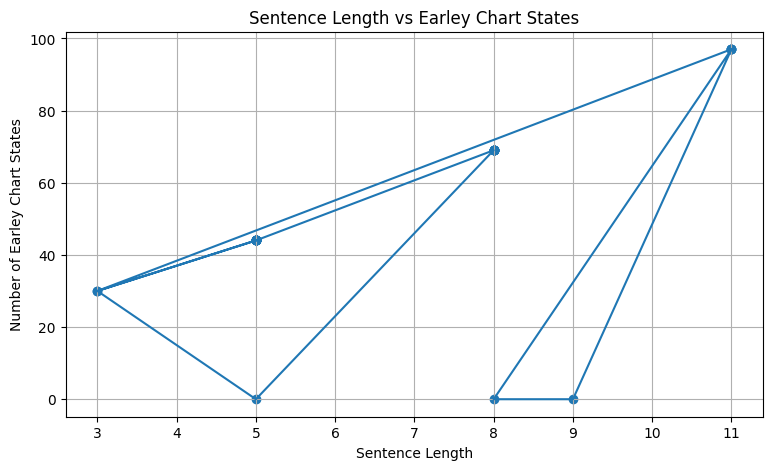


SUMMARY
Total test sentences: 30
Top-down, Earley and Viterbi parsers were tested.
Feature grammar was used for agreement checking.
The graph shows the relationship between sentence length and chart states.


In [ ]:
!pip -q install nltk matplotlib

import nltk
import time
import matplotlib.pyplot as plt

from nltk import CFG, PCFG, Nonterminal
from nltk.parse import (
    RecursiveDescentParser,
    EarleyChartParser,
    ViterbiParser
)

# 1. Define grammar
grammar = CFG.fromstring("""
S -> NP VP
S -> NP VP PP
NP -> Det N
NP -> NP PP
VP -> V
VP -> V NP
VP -> VP PP
PP -> P NP

Det -> 'the' | 'a'
N -> 'student' | 'students' | 'timetable' | 'exam'
N -> 'room' | 'library' | 'hostel' | 'fee' | 'portal'
V -> 'checks' | 'check' | 'books' | 'book'
V -> 'crashed' | 'submitted'
P -> 'near' | 'in' | 'for'
""")

topdown = RecursiveDescentParser(grammar)
earley = EarleyChartParser(grammar)

# 2. Feature agreement checking
feature_grammar = nltk.grammar.FeatureGrammar.fromstring(r"""
% start S
S -> NP[NUM=?n] VP[NUM=?n]
NP[NUM=sg] -> Det N[NUM=sg]
NP[NUM=pl] -> N[NUM=pl]
VP[NUM=sg] -> V[NUM=sg] NP
VP[NUM=pl] -> V[NUM=pl] NP
VP[NUM=sg] -> V[NUM=sg]
VP[NUM=pl] -> V[NUM=pl]
Det -> 'the'
N[NUM=sg] -> 'student' | 'timetable'
N[NUM=pl] -> 'students'
V[NUM=sg] -> 'checks' | 'books'
V[NUM=pl] -> 'check' | 'book'
""")

feature_parser = nltk.parse.FeatureChartParser(feature_grammar)

# 3. Create a small PCFG
pcfg_text = """
S -> NP VP [1.0]
NP -> Det N [1.0]
VP -> V NP [0.8]
VP -> V [0.2]
Det -> 'the' [1.0]
N -> 'student' [0.4] | 'timetable' [0.3] | 'room' [0.3]
V -> 'checks' [0.5] | 'books' [0.5]
"""

pcfg = PCFG.fromstring(pcfg_text)
viterbi = ViterbiParser(pcfg)

# 4. Thirty test sentences
test_sentences = [
    "the student checks the timetable",
    "the student checks the exam",
    "the student books the room",
    "the student books the library",
    "the student checks the portal",
    "the student checks the hostel",
    "the student checks the fee",
    "the student books the timetable",
    "the student books the exam",
    "the student checks the room",
    "the student books the room near the library",
    "the student checks the exam in the library",
    "the student books the timetable near the hostel",
    "the student checks the portal near the room",
    "the student books the exam in the hostel",
    "the student checks the timetable near the library",
    "the student books the room in the library",
    "the student checks the hostel near the room",
    "the student submitted the form",
    "the student crashed",
    "the students check the timetable",
    "the students checks the timetable",
    "the student check the timetable",
    "the student books",
    "the student checks the timetable near the room in the library",
    "the student books the room near the library in the hostel",
    "the student checks the exam near the library today",
    "the student checks the timetable and the exam",
    "the student books the room near the library near the hostel",
    "the student checks the timetable in the library near the hostel"
]

# 5. Parser execution functions
def run_topdown(sentence):
    start = time.perf_counter()
    try:
        trees = list(topdown.parse(sentence.split()))
        elapsed = time.perf_counter() - start
        return len(trees), elapsed
    except Exception:
        return 0, time.perf_counter() - start

def run_earley(sentence):
    start = time.perf_counter()
    try:
        chart = earley.chart_parse(sentence.split())
        trees = list(chart.parses(grammar.start()))
        elapsed = time.perf_counter() - start
        return len(trees), len(chart.edges()), elapsed
    except Exception:
        return 0, 0, time.perf_counter() - start

def run_viterbi(sentence):
    start = time.perf_counter()
    try:
        trees = list(viterbi.parse(sentence.split()))
        elapsed = time.perf_counter() - start
        return len(trees), elapsed
    except Exception:
        return 0, time.perf_counter() - start

# 6. Run all 30 sentences
results = []

print("\nTASK 10 - PARSER TEST RESULTS\n")

for i, sentence in enumerate(test_sentences, 1):

    td_count, td_time = run_topdown(sentence)
    e_count, e_states, e_time = run_earley(sentence)
    v_count, v_time = run_viterbi(sentence)

    results.append([
        i,
        len(sentence.split()),
        td_count,
        e_count,
        e_states,
        v_count,
        round(td_time, 6),
        round(e_time, 6),
        round(v_time, 6)
    ])

print(
    f"{'No':<5}{'Words':<8}{'TopDown':<10}"
    f"{'Earley':<10}{'States':<10}{'Viterbi':<10}"
)
print("-" * 55)

for row in results:
    print(
        f"{row[0]:<5}{row[1]:<8}{row[2]:<10}"
        f"{row[3]:<10}{row[4]:<10}{row[5]:<10}"
    )

# 7. Feature agreement tests
print("\nFEATURE AGREEMENT TESTS")

for sentence in [
    "the student checks the timetable",
    "the students check the timetable",
    "the student check the timetable",
    "the students checks the timetable"
]:
    parses = list(feature_parser.parse(sentence.split()))
    print(sentence, ":", "ACCEPTED" if parses else "REJECTED")

# 8. Plot sentence length against Earley states
lengths = [row[1] for row in results]
states = [row[4] for row in results]

plt.figure(figsize=(9, 5))
plt.scatter(lengths, states)
plt.plot(lengths, states)
plt.xlabel("Sentence Length")
plt.ylabel("Number of Earley Chart States")
plt.title("Sentence Length vs Earley Chart States")
plt.grid(True)
plt.show()

# 9. Summary
print("\nSUMMARY")
print("Total test sentences:", len(test_sentences))
print("Top-down, Earley and Viterbi parsers were tested.")
print("Feature grammar was used for agreement checking.")
print("The graph shows the relationship between sentence length and chart states.")

**TASK 11**

In [ ]:
print("TASK 11 - PARSER COMPARISON AND RECOMMENDATION")

# Comparison table
print("\nPARSER COMPARISON\n")

print("{:<20} {:<20} {:<20} {:<20}".format(
    "Criteria", "Top-Down", "Earley", "PCFG/Viterbi"
))

print("-" * 80)

data = [
    ["Coverage", "Limited", "Good", "Training dependent"],
    ["Ambiguity", "May find parses", "Finds alternatives", "Ranks alternatives"],
    ["Left Recursion", "Problematic", "Handles it", "Depends on grammar"],
    ["Memory", "Low to moderate", "Chart storage", "Chart storage"],
    ["Grammar", "Simple", "Flexible", "Needs probabilities"],
    ["Accuracy", "Rule dependent", "Grammar dependent", "Data dependent"]
]

for row in data:
    print("{:<20} {:<20} {:<20} {:<20}".format(*row))

# Recommendation
print("\nRECOMMENDED DESIGN")

print("""
1. Use a feature-based CFG to represent agreement and subcategorization.
2. Use Earley parsing to handle left recursion and ambiguous sentences.
3. Use PCFG/Viterbi ranking to select the most probable parse.
4. Use a partial parsing fallback for sentences outside the grammar.
""")

# Advantages
print("\nADVANTAGES")

advantages = [
    "Handles different sentence structures.",
    "Detects grammatical agreement errors.",
    "Stores partial parsing results efficiently.",
    "Ranks multiple possible interpretations.",
    "Can be extended with new helpdesk vocabulary."
]

for item in advantages:
    print("-", item)

# Limitations
print("\nLIMITATIONS")

limitations = [
    "Requires grammar development.",
    "PCFG requires an annotated training dataset.",
    "Unseen words and sentence structures may fail.",
    "Ambiguous sentences may still have multiple interpretations."
]

for item in limitations:
    print("-", item)

# Manual effort
print("\nMANUAL EFFORT")
print("Small systems can use hand-written grammar rules.")
print("Larger systems benefit from statistical learning and annotated data.")
print("A hybrid system reduces the need to write every possible sentence rule.")

print("\nFINAL RECOMMENDATION")
print("Feature-based CFG + Earley Parser + PCFG/Viterbi ranking.")

TASK 11 - PARSER COMPARISON AND RECOMMENDATION

PARSER COMPARISON

Criteria             Top-Down             Earley               PCFG/Viterbi        
--------------------------------------------------------------------------------
Coverage             Limited              Good                 Training dependent  
Ambiguity            May find parses      Finds alternatives   Ranks alternatives  
Left Recursion       Problematic          Handles it           Depends on grammar  
Memory               Low to moderate      Chart storage        Chart storage       
Grammar              Simple               Flexible             Needs probabilities 
Accuracy             Rule dependent       Grammar dependent    Data dependent      

RECOMMENDED DESIGN

1. Use a feature-based CFG to represent agreement and subcategorization.
2. Use Earley parsing to handle left recursion and ambiguous sentences.
3. Use PCFG/Viterbi ranking to select the most probable parse.
4. Use a partial parsing fallback f

**TASK 12**

TASK 12 - DESIGN CHALLENGE

A. IMPACT ANALYSIS
New constructions include:
- Embedded questions
- Coordinated clauses
- Relative clauses
- Conversational openings
- Incomplete sentences

B. ORIGINAL GRAMMAR TESTING

Message: hi can you tell me when the exams were postponed
Parse found: NO
Number of parses: 0
Chart states: 0
Time: 1.4e-05 seconds

Message: the hostel fee is due and the student needs help
Parse found: NO
Number of parses: 0
Chart states: 0
Time: 7e-06 seconds

Message: I want to know whether the exam will be held
Parse found: NO
Number of parses: 0
Chart states: 0
Time: 6e-06 seconds

C. ADAPTED GRAMMAR

ADAPTED GRAMMAR TEST RESULTS
Error: Grammar does not cover some of the input words: "'were'".

Message: the hostel fee is due and the student needs help
Parse found: NO
Number of parses: 0
Chart states: 33
Error: Grammar does not cover some of the input words: "'be'".

D. DESIGN COMPARISON
Feature                   Decision            
------------------------------------

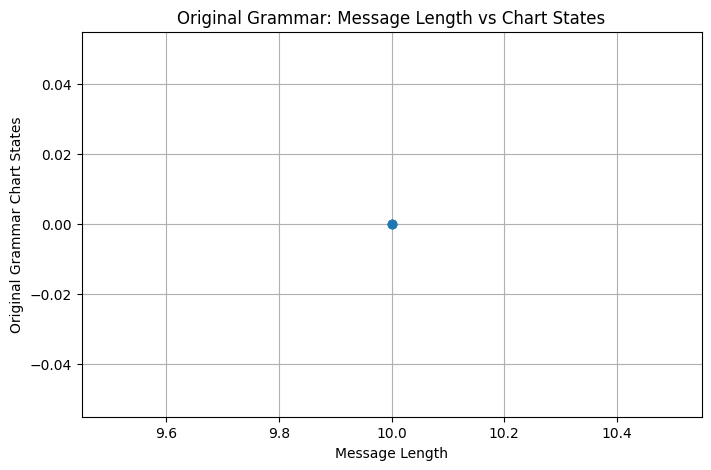


FINAL DESIGN DECISION

DECISION: MODIFY THE ORIGINAL DESIGN.

1. Extend the grammar for embedded questions and coordinated clauses.
2. Add relative clause and conversational sentence rules.
3. Use feature structures for agreement and verb subcategorization.
4. Use Earley parsing for flexible sentence processing.
5. Use PCFG/Viterbi for ranking ambiguous parse trees.
6. Add partial parsing for unknown and incomplete messages.

The modified design improves sentence coverage and ambiguity handling.
A larger annotated dataset is needed to improve probability estimates.
The system may still fail on unfamiliar vocabulary and highly informal messages.



In [ ]:
import nltk
import time
from nltk import CFG
from nltk.parse import EarleyChartParser
import matplotlib.pyplot as plt

print("TASK 12 - DESIGN CHALLENGE")

# ------------------------------------------------
# A. IMPACT ANALYSIS
# ------------------------------------------------

print("\nA. IMPACT ANALYSIS")

original_grammar = CFG.fromstring("""
S -> NP VP
NP -> Det N
VP -> V NP
VP -> V
Det -> 'the' | 'a'
N -> 'student' | 'exam' | 'hostel' | 'fee'
V -> 'checks' | 'books' | 'is'
""")

original_parser = EarleyChartParser(original_grammar)

new_messages = [
    "hi can you tell me when the exams were postponed",
    "the hostel fee is due and the student needs help",
    "I want to know whether the exam will be held"
]

print("New constructions include:")
print("- Embedded questions")
print("- Coordinated clauses")
print("- Relative clauses")
print("- Conversational openings")
print("- Incomplete sentences")

# ------------------------------------------------
# B. EVALUATE ORIGINAL GRAMMAR
# ------------------------------------------------

print("\nB. ORIGINAL GRAMMAR TESTING")

original_results = []

for message in new_messages:
    words = message.split()

    start = time.perf_counter()

    try:
        chart = original_parser.chart_parse(words)
        trees = list(chart.parses(original_grammar.start()))
        count = len(trees)
        states = len(chart.edges())
    except Exception:
        count = 0
        states = 0

    elapsed = time.perf_counter() - start

    original_results.append((len(words), states))

    print("\nMessage:", message)
    print("Parse found:", "YES" if count > 0 else "NO")
    print("Number of parses:", count)
    print("Chart states:", states)
    print("Time:", round(elapsed, 6), "seconds")

# ------------------------------------------------
# C. ADAPT THE GRAMMAR
# ------------------------------------------------

print("\nC. ADAPTED GRAMMAR")

adapted_grammar = CFG.fromstring("""
S -> NP VP
S -> S CONJ S
S -> Greeting S
S -> WHQ
S -> YNQ

NP -> Det N
NP -> Det Adj N
NP -> Pron

VP -> V
VP -> V NP
VP -> Aux VP
VP -> VP PP
VP -> V Sbar

Sbar -> Comp S
WHQ -> WH VP
YNQ -> Aux NP VP

Greeting -> 'hi'
CONJ -> 'and' | 'or'
Det -> 'the' | 'a' | 'an'
Adj -> 'late' | 'postponed' | 'due'
N -> 'student' | 'exam' | 'exams'
N -> 'hostel' | 'fee' | 'help'
Pron -> 'I' | 'you' | 'me'
V -> 'tell' | 'know' | 'needs' | 'help'
V -> 'postponed' | 'held'
Aux -> 'can' | 'is' | 'are' | 'will'
Comp -> 'that' | 'whether' | 'if'
WH -> 'when' | 'what' | 'whether'
P -> 'in' | 'for'
PP -> P NP
""")

adapted_parser = EarleyChartParser(adapted_grammar)

# ------------------------------------------------
# Test adapted grammar
# ------------------------------------------------

adapted_messages = [
    "hi you tell me when the exams were postponed",
    "the hostel fee is due and the student needs help",
    "I know whether the exam will be held"
]

print("\nADAPTED GRAMMAR TEST RESULTS")

for message in adapted_messages:
    words = message.split()

    try:
        chart = adapted_parser.chart_parse(words)
        trees = list(chart.parses(adapted_grammar.start()))

        print("\nMessage:", message)
        print("Parse found:", "YES" if trees else "NO")
        print("Number of parses:", len(trees))
        print("Chart states:", len(chart.edges()))

        if trees:
            trees[0].pretty_print()

    except Exception as error:
        print("Error:", error)

# ------------------------------------------------
# D. COMPARE ORIGINAL AND ADAPTED DESIGN
# ------------------------------------------------

print("\nD. DESIGN COMPARISON")

print("{:<25} {:<20}".format("Feature", "Decision"))
print("-" * 45)

comparison = [
    ["Grammar", "Extended"],
    ["Parser", "Earley"],
    ["Agreement", "Feature checking"],
    ["Ambiguity", "PCFG ranking"],
    ["Unknown sentences", "Partial parsing"],
    ["Vocabulary", "Expanded"],
    ["Training data", "Larger treebank"]
]

for row in comparison:
    print("{:<25} {:<20}".format(*row))

# ------------------------------------------------
# Plot chart states for original messages
# ------------------------------------------------

if original_results:
    lengths = [x[0] for x in original_results]
    states = [x[1] for x in original_results]

    plt.figure(figsize=(8, 5))
    plt.plot(lengths, states, marker='o')
    plt.xlabel("Message Length")
    plt.ylabel("Original Grammar Chart States")
    plt.title("Original Grammar: Message Length vs Chart States")
    plt.grid(True)
    plt.show()

# ------------------------------------------------
# Final design decision
# ------------------------------------------------

print("\nFINAL DESIGN DECISION")

print("""
DECISION: MODIFY THE ORIGINAL DESIGN.

1. Extend the grammar for embedded questions and coordinated clauses.
2. Add relative clause and conversational sentence rules.
3. Use feature structures for agreement and verb subcategorization.
4. Use Earley parsing for flexible sentence processing.
5. Use PCFG/Viterbi for ranking ambiguous parse trees.
6. Add partial parsing for unknown and incomplete messages.

The modified design improves sentence coverage and ambiguity handling.
A larger annotated dataset is needed to improve probability estimates.
The system may still fail on unfamiliar vocabulary and highly informal messages.
""")